<a href="https://colab.research.google.com/github/SithmiDesilva/Hallucination-Aware-AI-Framework-for-Trustworthy-Supply-Chain-Decision-Intelligence.-/blob/DataCo_Supply_Chain_Preprocessing/DataCo_Supply_Chain_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SECTION 1: INITIAL SETUP AND DATA LOADING

In [2]:

!pip install pandas numpy matplotlib seaborn scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')


from google.colab import drive
drive.mount('/content/drive')

plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)


file_path = '/content/drive/MyDrive/IRP/Data Co/DataCoSupplyChainDataset.csv'

try:
    df_raw = pd.read_csv(file_path, encoding='latin1')
    print(f" Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
    print(f"\nFirst 8 columns: {list(df_raw.columns[:8])}")
    print(f"Last 5 columns: {list(df_raw.columns[-5:])}")
except Exception as e:
    print(f" Load error: {e}")
    df_raw = None

df_raw.head(3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Loaded: 180,519 rows × 53 columns

First 8 columns: ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id']
Last 5 columns: ['Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrders)', 'Shipping Mode']


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


## SECTION 2: DATA INSPECTION BEFORE PREPROCESSING

In [3]:
# 2.1 Structure
print("\n--- Shape & Types ---")
print(f"Rows: {df_raw.shape[0]:,}  |  Columns: {df_raw.shape[1]}")

# Count by dtype
dtype_counts = df_raw.dtypes.value_counts()
print(f"\nDtype distribution:\n{dtype_counts.to_string()}")

# 2.2 Missing values
print("\n--- Missing Values (top 10) ---")
missing_df = pd.DataFrame({
    'Column': df_raw.columns,
    'Missing_Count': df_raw.isnull().sum().values,
    'Missing_Pct': (df_raw.isnull().sum() / len(df_raw) * 100).values
}).sort_values('Missing_Pct', ascending=False)

missing_nonzero = missing_df[missing_df['Missing_Count'] > 0]
print(missing_nonzero.to_string(index=False) if len(missing_nonzero) else "No missing values")

# 2.3 Categorical cardinality
print("\n--- Categorical Cardinality (top 10) ---")
obj_cols = df_raw.select_dtypes(include='object').columns
cardinality = pd.DataFrame({
    'Column': obj_cols,
    'Unique': [df_raw[c].nunique() for c in obj_cols]
}).sort_values('Unique', ascending=False)
print(cardinality.head(10).to_string(index=False))

# 2.4 Numerical summary
print("\n--- Numerical Summary ---")
num_cols = df_raw.select_dtypes(include=np.number).columns
df_raw[num_cols].describe().round(2)


--- Shape & Types ---
Rows: 180,519  |  Columns: 53

Dtype distribution:
object     24
float64    15
int64      14

--- Missing Values (top 10) ---
             Column  Missing_Count  Missing_Pct
Product Description         180519   100.000000
      Order Zipcode         155679    86.239676
     Customer Lname              8     0.004432
   Customer Zipcode              3     0.001662

--- Categorical Cardinality (top 10) ---
                    Column  Unique
   order date (DateOrders)   65752
shipping date (DateOrders)   63701
           Customer Street    7458
                Order City    3597
            Customer Lname    1109
               Order State    1089
            Customer Fname     782
             Customer City     563
             Order Country     164
             Product Image     118

--- Numerical Summary ---


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,Longitude,Order Customer Id,Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180516.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,24840.00,180519.00,180519.00,0.0,180519.00,180519.0
mean,3.50,2.93,21.97,183.11,0.55,31.85,6691.38,35921.13,5.44,29.72,-84.92,6691.38,36221.89,692.51,20.66,0.10,90260.00,141.23,0.12,2.13,203.77,183.11,21.97,55426.13,692.51,31.85,NaN,141.23,0.0
std,1.62,1.37,104.43,120.04,0.50,15.64,4162.92,37542.46,1.63,9.81,21.43,4162.92,21045.38,336.45,21.80,0.07,52111.49,139.73,0.47,1.45,132.27,120.04,104.43,31919.28,336.45,15.64,NaN,139.73,0.0
min,0.00,0.00,-4274.98,7.49,0.00,2.00,1.00,603.00,2.00,-33.94,-158.03,1.00,1.00,19.00,0.00,0.00,1.00,9.99,-2.75,1.00,9.99,7.49,-4274.98,1040.00,19.00,2.00,NaN,9.99,0.0
25%,2.00,2.00,7.00,104.38,0.00,18.00,3258.50,725.00,4.00,18.27,-98.45,3258.50,18057.00,403.00,5.40,0.04,45130.50,50.00,0.08,1.00,119.98,104.38,7.00,23464.00,403.00,18.00,NaN,50.00,0.0
50%,3.00,4.00,31.52,163.99,1.00,29.00,6457.00,19380.00,5.00,33.14,-76.85,6457.00,36140.00,627.00,14.00,0.10,90260.00,59.99,0.27,1.00,199.92,163.99,31.52,59405.00,627.00,29.00,NaN,59.99,0.0
75%,5.00,4.00,64.80,247.40,1.00,45.00,9779.00,78207.00,7.00,39.28,-66.37,9779.00,54144.00,1004.00,29.99,0.16,135389.50,199.99,0.36,3.00,299.95,247.40,64.80,90008.00,1004.00,45.00,NaN,199.99,0.0
max,6.00,4.00,911.80,1939.99,1.00,76.00,20757.00,99205.00,12.00,48.78,115.26,20757.00,77204.00,1363.00,500.00,0.25,180519.00,1999.99,0.50,5.00,1999.99,1939.99,911.80,99301.00,1363.00,76.00,NaN,1999.99,0.0


## SECTION 3: BEFORE PREPROCESSING VISUALIZATIONS

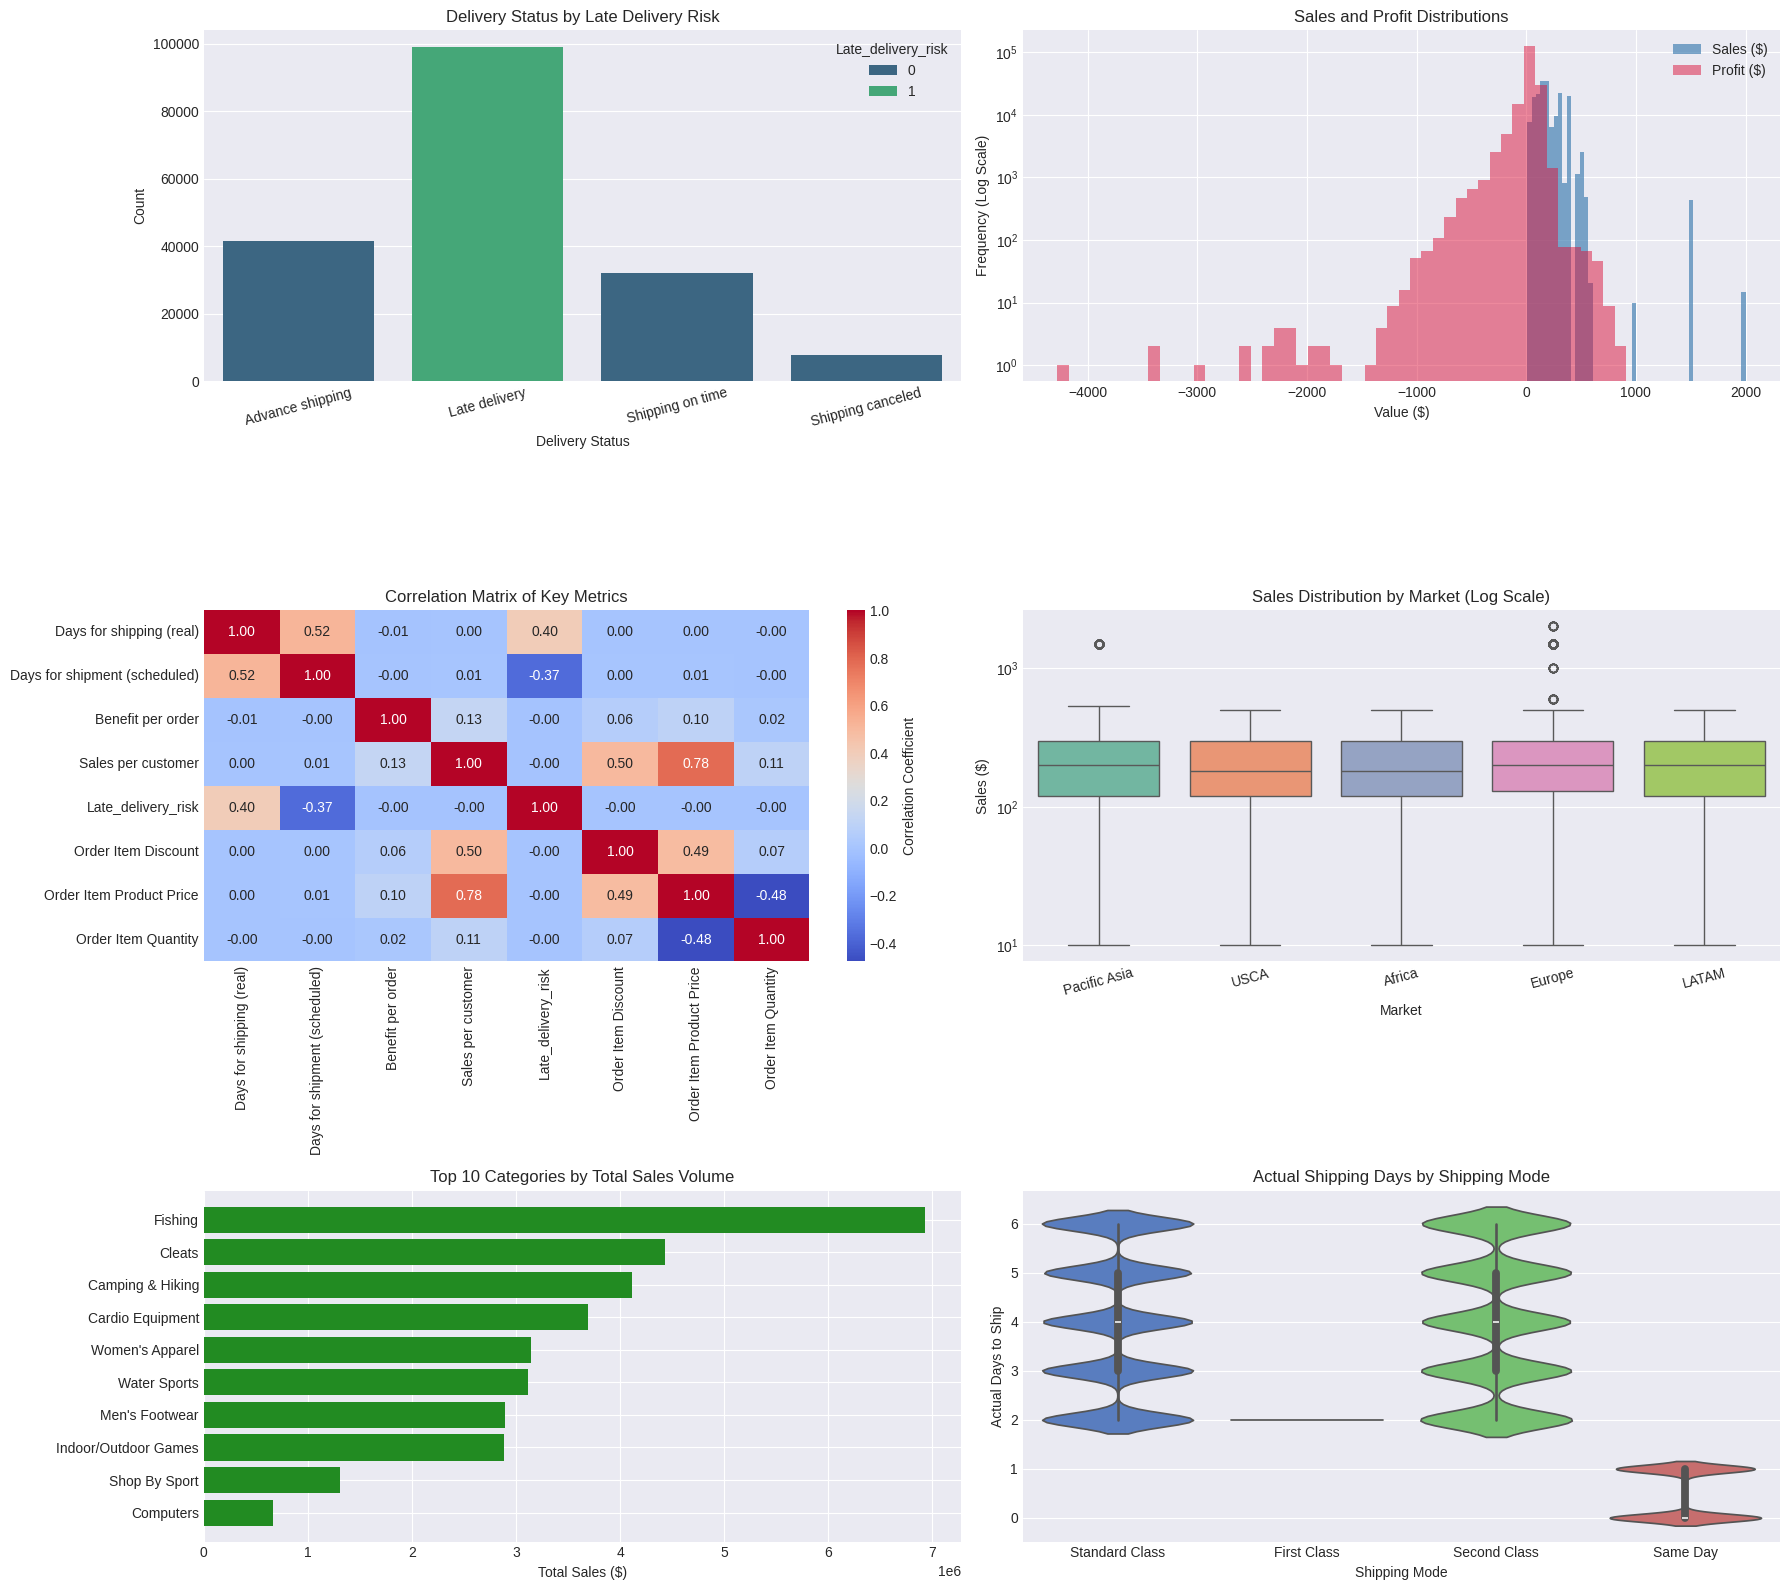

In [7]:
# Configure a 3x2 visualization grid for deeper insights
fig, axes = plt.subplots(3, 2, figsize=(18, 16))

# 1. Target Distribution: Late Delivery Risk vs Delivery Status
sns.countplot(data=df_raw, x='Delivery Status', hue='Late_delivery_risk', ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Delivery Status by Late Delivery Risk', fontsize=12)
axes[0,0].set_xticklabels(axes[0,0].get_xticklabels(), rotation=15)
axes[0,0].set_xlabel('Delivery Status')
axes[0,0].set_ylabel('Count')

# 2. Financial Metrics Distribution (Sales vs Benefit per order)
axes[0,1].hist(df_raw['Sales'].dropna(), bins=50, alpha=0.7, label='Sales ($)', color='steelblue')
axes[0,1].hist(df_raw['Benefit per order'].dropna(), bins=50, alpha=0.5, label='Profit ($)', color='crimson')
axes[0,1].set_title('Sales and Profit Distributions', fontsize=12)
axes[0,1].set_yscale('log')
axes[0,1].set_xlabel('Value ($)')
axes[0,1].set_ylabel('Frequency (Log Scale)')
axes[0,1].legend()

# 3. Correlation Heatmap of Numeric Features
corr_cols = [
    'Days for shipping (real)', 'Days for shipment (scheduled)',
    'Benefit per order', 'Sales per customer', 'Late_delivery_risk',
    'Order Item Discount', 'Order Item Product Price', 'Order Item Quantity'
]
corr_matrix = df_raw[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1,0], cbar_kws={'label': 'Correlation Coefficient'})
axes[1,0].set_title('Correlation Matrix of Key Metrics', fontsize=12)

# 4. Sales Distribution by Market Region
sns.boxplot(data=df_raw, x='Market', y='Sales', ax=axes[1,1], palette='Set2')
axes[1,1].set_yscale('log')
axes[1,1].set_title('Sales Distribution by Market (Log Scale)', fontsize=12)
axes[1,1].set_xlabel('Market')
axes[1,1].set_ylabel('Sales ($)')
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=15)

# 5. Top 10 Product Categories by Revenue (Sales)
cat_sales = df_raw.groupby('Category Name')['Sales'].sum().sort_values(ascending=False).head(10)
axes[2,0].barh(cat_sales.index, cat_sales.values, color='forestgreen')
axes[2,0].set_title('Top 10 Categories by Total Sales Volume', fontsize=12)
axes[2,0].set_xlabel('Total Sales ($)')
axes[2,0].invert_yaxis()

# 6. Scheduled vs Actual Shipping Days Analysis
sns.violinplot(data=df_raw, x='Shipping Mode', y='Days for shipping (real)', ax=axes[2,1], palette='muted')
axes[2,1].set_title('Actual Shipping Days by Shipping Mode', fontsize=12)
axes[2,1].set_xlabel('Shipping Mode')
axes[2,1].set_ylabel('Actual Days to Ship')

plt.tight_layout()
plt.savefig('comprehensive_eda.png', dpi=150, bbox_inches='tight')
plt.show()

## SECTION 4: HANDLE MISSING VALUES

In [8]:
df = df_raw.copy()
missing_before = df.isnull().sum().sum()
print(f"Total missing cells BEFORE: {missing_before:,}")

# 4.1 Drop columns with >50% missing
threshold_pct = 50
drop_cols = []
for col in df.columns:
    pct = df[col].isnull().mean() * 100
    if pct > threshold_pct:
        drop_cols.append((col, pct))

print(f"\nColumns to drop (>50% missing):")
for col, pct in drop_cols:
    print(f"  - {col}: {pct:.1f}%")
df = df.drop(columns=[c for c, _ in drop_cols])

# 4.2 Smart imputation (avoid nonsense like zipcode median)
imputations = []

for col in df.columns:
    n_miss = df[col].isnull().sum()
    if n_miss == 0:
        continue

    if pd.api.types.is_numeric_dtype(df[col]) and col.lower() not in ('customer_zipcode', 'order_zipcode'):
        # Numeric (non-identifier): use median
        val = df[col].median()
        df[col] = df[col].fillna(val)
        imputations.append((col, 'median', f'{val:.2f}', n_miss))
    else:
        # Categorical or identifier: use 'Unknown' or mode
        if col.lower().endswith('zipcode'):
            df[col] = df[col].fillna('Unknown')
            imputations.append((col, 'unknown', 'Unknown', n_miss))
        else:
            mode_val = df[col].mode()
            if len(mode_val):
                df[col] = df[col].fillna(mode_val[0])
                imputations.append((col, 'mode', str(mode_val[0])[:25], n_miss))

print(f"\nImputations applied:")
for col, method, val, n in imputations:
    print(f"  {col:<30} {n:>6,} → {method} ({val})")

print(f"\nTotal missing AFTER: {df.isnull().sum().sum()}")
print(f"Shape after drop: {df.shape}")

Total missing cells BEFORE: 336,209

Columns to drop (>50% missing):
  - Order Zipcode: 86.2%
  - Product Description: 100.0%

Imputations applied:
  Customer Lname                      8 → mode (Smith)
  Customer Zipcode                    3 → median (19380.00)

Total missing AFTER: 0
Shape after drop: (180519, 51)


## SECTION 5: DUPLICATE AND COLUMN NAME STANDARDIZATION

In [9]:
# 5.1 Duplicates
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count:,}")
if dup_count > 0:
    df = df.drop_duplicates(keep='first')
    print(f"✓ Removed {dup_count:,} duplicates")

# 5.2 Standardize column names
rename_map = {}
for col in df.columns:
    new = col.lower()
    new = new.replace(' ', '_').replace('-', '_').replace('/', '_').replace('(', '').replace(')', '')
    new = '_'.join([p for p in new.split('_') if p])
    rename_map[col] = new

df = df.rename(columns=rename_map)
print(f"\nExample renames:")
for old, new in list(rename_map.items())[:6]:
    print(f"  {old:<35} → {new}")

print(f"\nNew shape: {df.shape}")

Duplicate rows: 0

Example renames:
  Type                                → type
  Days for shipping (real)            → days_for_shipping_real
  Days for shipment (scheduled)       → days_for_shipment_scheduled
  Benefit per order                   → benefit_per_order
  Sales per customer                  → sales_per_customer
  Delivery Status                     → delivery_status

New shape: (180519, 51)


## SECTION 6: DATA TYPE CORRECTION

In [11]:
# 6.1 Parse REAL date columns only (explicit list, not keyword matching)
date_columns = ['order_date_dateorders', 'shipping_date_dateorders']
for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')
        valid = df[col].notna().sum()
        print(f" {col} → datetime64  ({valid:,} valid = {valid/len(df)*100:.1f}%)")
        print(f"  Range: {df[col].min()} → {df[col].max()}")

# 6.2 Convert LOW-CARDINALITY object columns to category (but skip high-cardinality ID-like)
print(f"\nConverting low-cardinality columns to category:")
cat_converted = []
for col in df.select_dtypes(include='object').columns:
    n_unique = df[col].nunique()
    # Skip PII / ID-like columns
    if any(tok in col for tok in ['email', 'password', 'street', 'name', 'id']):
        continue
    if 1 < n_unique <= 50:
        df[col] = df[col].astype('category')
        cat_converted.append((col, n_unique))

for col, n in cat_converted:
    print(f"  {col:<35} → category ({n} levels)")

# 6.3 Sanity check
print(f"\n--- Final dtype distribution ---")
print(df.dtypes.value_counts().to_string())

 order_date_dateorders → datetime64  (180,519 valid = 100.0%)
  Range: 2015-01-01 00:00:00 → 2018-01-31 23:38:00
 shipping_date_dateorders → datetime64  (180,519 valid = 100.0%)
  Range: 2015-01-03 00:00:00 → 2018-02-06 22:14:00

Converting low-cardinality columns to category:

--- Final dtype distribution ---
int64             14
object            13
float64           13
datetime64[ns]     2
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1


## SECTION 7: OUTLIER DETECTION AND CAPPING

In [12]:
# Only these make sense to cap — skip identifiers, coordinates, dates
exclude_tokens = ['id', 'code', 'year', 'month', 'day', 'date', 'latitude', 'longitude', 'zipcode']
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols = [c for c in num_cols if not any(t in c for t in exclude_tokens)]

outlier_summary = []

for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    if IQR == 0:
        continue
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    pct = n_out / len(df) * 100

    if n_out > 0 and pct < 10:      # Cap only if less than 10% are outliers
        df[col] = df[col].clip(lower, upper)
        outlier_summary.append({
            'Column': col, 'Capped': n_out, 'Pct': round(pct, 2),
            'Lower': round(lower, 2), 'Upper': round(upper, 2)
        })

if outlier_summary:
    print(pd.DataFrame(outlier_summary).to_string(index=False))
else:
    print("No outliers capped.")

                  Column  Capped  Pct   Lower  Upper
      sales_per_customer    1943 1.08 -110.15 461.93
     order_item_discount    7537 4.18  -31.48  66.87
order_item_product_price    2048 1.13 -174.99 424.98
 order_item_profit_ratio   17300 9.58   -0.34   0.78
                   sales     488 0.27 -149.98 569.91
        order_item_total    1943 1.08 -110.15 461.93
           product_price    2048 1.13 -174.99 424.98


## SECTION 8: FEATURE ENGINEERING

In [13]:
# 8.1 Date features (now the datetime columns actually exist)
date_col = 'order_date_dateorders'
df['order_year']      = df[date_col].dt.year
df['order_month']     = df[date_col].dt.month
df['order_day']       = df[date_col].dt.day
df['order_dayofweek'] = df[date_col].dt.dayofweek   # 0=Mon
df['order_quarter']   = df[date_col].dt.quarter
print(f"✓ Created 5 date features from {date_col}")

# 8.2 Shipping delay
ship_col = 'shipping_date_dateorders'
df['shipping_days']    = (df[ship_col] - df[date_col]).dt.days.clip(lower=0)
df['shipping_delay']   = df['days_for_shipping_real'] - df['days_for_shipment_scheduled']
df['is_late_delivery'] = (df['shipping_delay'] > 0).astype(int)
print(f"✓ shipping_days, shipping_delay, is_late_delivery created")
print(f"  Late deliveries: {df['is_late_delivery'].sum():,} ({df['is_late_delivery'].mean()*100:.1f}%)")

# 8.3 Profit features
df['profit_margin_pct'] = (df['order_profit_per_order'] / df['sales'].replace(0, np.nan)) * 100
df['profit_margin_pct'] = df['profit_margin_pct'].replace([np.inf, -np.inf], np.nan).fillna(0)
print(f"✓ profit_margin_pct created")

# 8.4 Discount feature (already numeric; just an indicator)
df['has_discount'] = (df['order_item_discount'] > 0).astype(int)
print(f"✓ has_discount created ({df['has_discount'].mean()*100:.1f}% of orders)")

# 8.5 Customer full name
df['customer_full_name'] = df['customer_fname'].astype(str) + ' ' + df['customer_lname'].astype(str)
print(f"✓ customer_full_name created")

print(f"\nShape now: {df.shape}")

✓ Created 5 date features from order_date_dateorders
✓ shipping_days, shipping_delay, is_late_delivery created
  Late deliveries: 103,400 (57.3%)
✓ profit_margin_pct created
✓ has_discount created (94.4% of orders)
✓ customer_full_name created

Shape now: (180519, 62)
